# Google Earth Engine Basics

We are using Google Earth Engine (GEE) as our example of cloud computing. GEE has the advantage of being specifically tailored towards beginners in Earth Observation, as well as offering free ([but not unlimited](https://developers.google.com/earth-engine/guides/noncommercial_tiers)) compute allowance for noncommercial users such as students.

Some of you might have used GEE before, probably in the form of the online web GUI interface, which operates exclusively within JavaScript. Ultimately, GEE is neither JavaScript not Python, but simply [offers a (very similar) API across both languages to access GEE tools on the Google's servers](https://developers.google.com/earth-engine/guides/client_server). If you are more comfortable with the JavaScript version, you are welcome to continue to explore that. However, the Python API and associated tools is useful as we can work within our existing Jupyter Notebooks, and data can be downloaded directly into the familiar Python stack (e.g. `xarray` objects) for further anlaysis.

:::{warning}
Data visualisation of live Google Earth Engine data requires an active connection to the cloud. As a result, some components of this notebook won't be able to be visualised on the course website. Instead, it will require downloading the Notebook and running it yourself to see.
:::

## Installing and logging in in to GEE

You must have a GEE / Google Cloud setup to access GEE. Instructions were [distributed in the consolidation week instructions](../06/index.md).

Once you have signed up to GEE, make sure you have installed the required tools using `conda` ([or `mamba` if you have followed the instructions to accelerate your `conda` environment](../../backmatter/mamba.md)). The three packages we wish to install are `earthengine-api` (the official GEE package); `geemap` (which allows us to visualise GEE outputs within the Notebook); and `xee` (which allows us to download GEE items to `xarray` datasets).

```bash
conda activate gsc
conda install -c conda-forge earthengine-api geemap xee
```

Staying within the command line interface, ensure you are persitently logged in to GEE by running the command:

```bash
earthengine authenticate
```

This will open a browser window to approve access to your Google account. This is an optional step, but speeds things up down the line by avoiding you having to repeat this in every notebook.

Now we can import our libraries:



In [1]:
import ee      # The main Earth Engine library
import geemap  # A Python package for interactive mapping with Google Earth Engine
import xee     # Transfer data between Earth Engine and xarray

import rioxarray as rxr
import xarray as xr

from shapely.geometry import shape

We can now connect our notebook to GEE using `ee.Authenticate()` and `ee.Initialize()`. Think of this a bit like connecting to the STAC catalogue from earlier. 

You will need to provide the name of the project ID that you created. If in doubt, one potential way to find the project title is to go to [code.earthengine.google.com](https://code.earthengine.google.com/) and see the name in the top-right corner.

In [2]:
# =====================================
# Replace this with your own project id
my_project_name = "ee-trchudley"
# =====================================

ee.Authenticate()
ee.Initialize(project=my_project_name) 

## Searching for an Image

Some of the `ee` code in this Notebook may not seem very 'Pythonic', with a slightly strange syntax relative to what has emerged so far.

As mentioned, our Python commands here are what Google refers to as 'Client Libraries': an API 'wrapper'(https://developers.google.com/earth-engine/apidocs) that sends instructions on what to do to the _real_ Earth Engine on the cloud: this real Earth Engine is what is doing the computation. 

For those of you who have been introduced to the JavaScript version of GEE in the past, you will find that many of the functions are nearly identical. Indeed, there is only one [API Reference Documentation](https://developers.google.com/earth-engine/apidocs) that covers both JavaScript and Python: every [individual documentation page](https://developers.google.com/earth-engine/apidocs/ee-image-add) has a tab to view either JavaScript or Python implementations of the function (these are very useful!). As a result, if you happen to find useful, open-source Google Earth Engine code online that is written in JavaScript, it should be easy for you to convert this into a Python implementation.

The downside of all of this is that, technically, we aren't really "using Python" when we use the GEE API - we are simply sending commands to a remote machine. As a result, we can't naturally pass our normal array of geospatial Python objects to Earth Engine, and instead may have to create slightly different objects. For instance, rather than creating a `shapely` `box`, we have to use an `ee.Geometry.BBox` object:

In [3]:
bbox = [-2.76, 51.38, -2.43, 51.53] # xmin, ymin, xmax, ymax in lat/lon
aoi  = ee.Geometry.BBox(*bbox)

Google Earth Engine has a large online library of satellite and geospatial data, much like the Microsoft Planetary Computer STAC. You [can explore the Data Catalog here](https://developers.google.com/earth-engine/datasets): much like the Planetary Computer, there are useful code snippets to show how you can interact with the datasets. 

Landsat collections have a a consistent string pattern for requesting the catalog: for example, `"LANDSAT/LC08/C02/T1_L2"`. This means Landsat > Landsat 8 > Collection 2 > Tier 1 Imagery, at Level 2 (surface reflectance) processing. [Explore more of the Landsat catalogs here](https://developers.google.com/earth-engine/datasets/catalog/landsat). 

You can call a collection using the `ee.ImageCollection()` function. Unlike the `pystac_client` STAC search function, rather than filtering by providing arguments to a search function, you use built-in object functions. For example, `ee.ImageCollection("LANDSAT/LC09/C02/T1_L2").filterBounds(aoi)` will summon the Landsat 9 tier 1 surface reflectance catalog, filtered only to the scenes that intersect with the AOI we defined above.

We can chain together multiple filtering commands to produce an ["ImageCollection" (a collection of GEE satellite images)](https://developers.google.com/earth-engine/guides/ic_creating) to our liking:

In [4]:
date_min, date_max = '2023-05-01', '2023-09-30'

# Get Landsat 8 and 9 image collections, merged together
image_collection = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2").merge(ee.ImageCollection("LANDSAT/LC08/C02/T1_L2"))

# Begin filtering the image collection
image_collection = (
    image_collection
    .filterBounds(aoi)                         # Filter the collection to only include images that intersect with the area of interest
    .filterDate(date_min, date_max)            # Filter the collection to only include images within the specified date range
    .filter(ee.Filter.lt("CLOUD_COVER", 20))   # Filter the collection to only include images with less than 20% cloud cover
    .sort("CLOUD_COVER")                       # Sort the collection by cloud cover in ascending order
)

image_collection

Click the drop-down above to see that we have created an `ImageCollection` consisting of five images that fit our requirements. As we have sorted the data by cloud cover, we can select the `first()` image in our collection to see what an individual `Image` object looks like:

In [5]:
image_collection.first()

We can see that we have both OLI and TIRS (optical and thermal) bands, as well as 91 'properties' (image metadata) that we can further refine searches with. As an example, we use the `CLOUD_COVER` property to filter the search above, and you could add more if suitable. What you might filter in is probably quite use-case-specific: for instance, I have found need in the past to also filter by `SUN_ELEVATION` to find only images where the sun was high.

As we previously did with the Planetary Computer STAC, because we have sorted the image by cloudiness, we pick the `first()` image, select only the bands we need, and DN-correct and rename the bands to our liking. We can also `clip` the data to just our AOI. To see information about the bands, and how they are named, there is [a 'bands' tab within every Earth Engine catalog entry](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC09_C02_T1_L2#bands). 

In [6]:
image = (
    image_collection
    .first()
    .select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"])  # Select the surface reflectance bands (B2-B7)])
    .multiply(0.0000275).add(-0.2)
    .rename(["blue", "green", "red", "nir", "swir1", "swir2"])
    .clip(aoi)
)

image

If we wish to visualise what our image looks like without downloading it to our local environment, Google Earth Engine has a [slightly convoluted, but perfectly workable, image visualisation syntax](https://developers.google.com/earth-engine/guides/image_visualization), which can be accessed in a Jupyter Notebook via the `geemap` library.

I show you how to do visualise a simple RGB image in the below cell - but note that visualising this requires an active connection to GEE so you won't be able to see it on the course website. You will have to run this yourself in your own environment to see it!

In [ ]:
map = geemap.Map()

map.centerObject(aoi, zoom=11)

# Add the raw Landsat true-colour composite
# vis_params mirrors the GEE JavaScript Code Editor convention
vis_params = {
    "bands": ["red", "green", "blue"],   # our renamed bands
    "min": 0.0,                          # surface reflectance value which corresponds to black
    "max": 0.3,                          # surface reflectance value which corresponds to white
}

# Add the image to the map with the specified visualization parameters
map.addLayer(image, vis_params, name="Landsat 9 RGB")

# Visualise the map by calling the map object
map

## Image Operations

We can perform [typical band math](https://developers.google.com/earth-engine/guides/image_math) within Google Earth Engine. For instance, we could calculate NDIs for our image, such as NDVI: 

In [8]:
# Set string name of NDI to calculate
type_of_ndi = "ndvi"
r_high = 'red'  # relevant band name for r_high
r_low = 'nir'   # relevant band name for r_low

# calculate NDVI for image using multiply/add functions
ndi = image.select("nir").subtract(image.select("red")).divide(image.select("nir").add(image.select("red"))).rename(type_of_ndi)

However, as NDIs are such a common satellite operation, GEE actually has it's own `normalizedDifference()` function, where you only have to provide the bands you want to calculate your NDI from. The below cell produces an identical output to the above cell:

In [9]:
# Set string name of NDI to calculate
type_of_ndi = "ndvi"
r_high = 'nir'  # relevant band name for r_high
r_low = 'red'   # relevant band name for r_low

# calculate NDVI for image using multiply/add functions
ndi = image.normalizedDifference([r_high, r_low]).rename(type_of_ndi)

ndi

Note I have renamed the band to `"ndvi"` so we can keep track of what this object represents.

We can also visualise this using `geemap`. Unfortunately, the GEE visualisation tool doesn't come with a nice library of pre-named colourmaps, so I have had to provide my own. It ranges from brown to white to green, which feels appropriate for NDVI.

In [10]:
map = geemap.Map() # Create empty map

# Display colour image

# Display NDI
visParams = {'bands': ["ndvi"], 'min': -1, 'max': 1, 'palette': ['brown', 'white', 'green']}
map.addLayer(ndi, visParams, "ndvi")

map.centerObject(aoi, zoom=12)
map

Map(center=[51.45499752280457, -2.594999999999278], controls=(WidgetControl(options=['position', 'transparent_…

## Download to an `xarray` object

Using additional functionality provided by `xee`, we can download our processed data from the cloud to a local `xarray` object.

`xee` can only download ImageCollections, not Images, but we can easily convert our NDVI image back into a ImageCollection of length 1:

In [11]:
ndi_download_collection = ee.ImageCollection([ndi])

We also need to tell `xarray` the pixel grid to download: the coordinate reference system (CRS), the pixel size, and the area to cover. We can extract all of these from our `ndi` object: the CRS and pixel size from its `projection()`, and its footprint (returned as a lon/lat GeoJSON, which we convert to a `shapely` geometry) from its `geometry()`. `xee` then provides a helper function, `fit_geometry`, to convert these into the custom arguments we will need to provide to `xarray`.

Don't worry too much about the fine points of this - this code will look the same in any implementation you do yourself.

In [12]:
target_image = ndi

# Extract the CRS and pixel size from the image projection
projection = target_image.projection().getInfo()
crs = projection["crs"]
resolution = (projection["transform"][0], projection["transform"][4])  # (x, y) pixel size: y is negative as rows run north to south

# Extract the image footprint as a shapely geometry
footprint = shape(target_image.geometry().getInfo())

grid = xee.helpers.fit_geometry(footprint, grid_crs=crs, grid_scale=resolution)

print("grid parameters:", grid)


grid parameters: {'crs': 'EPSG:32630', 'crs_transform': (30.0, 0.0, 516630.0, 0.0, -30.0, 5708940.0), 'shape_2d': (768, 561)}


We can then transfer the GEE object to a local `xarray` object using `open_dataset` with the `'ee'` `engine` and the `grid` params from above:

In [13]:
ds = xr.open_dataset(
    ndi_download_collection,
    engine='ee',
    **grid
)

ds = ds.compute()

In [14]:
ds

<xarray.Dataset> Size: 2MB
Dimensions:  (time: 1, y: 561, x: 768)
Coordinates:
  * time     (time) int64 8B 0
  * y        (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x        (x) float64 6kB 5.166e+05 5.167e+05 ... 5.396e+05 5.397e+05
Data variables:
    ndvi     (time, y, x) float32 2MB nan nan nan nan nan ... nan nan nan nan

Simple! Note the structure: we have a `time` dimension (because we could hypothetically download an ImageCollection consisting of many images) and each of our bands (here, just `ndvi`) exist as an individual variable.

We can plot this in the usual way:

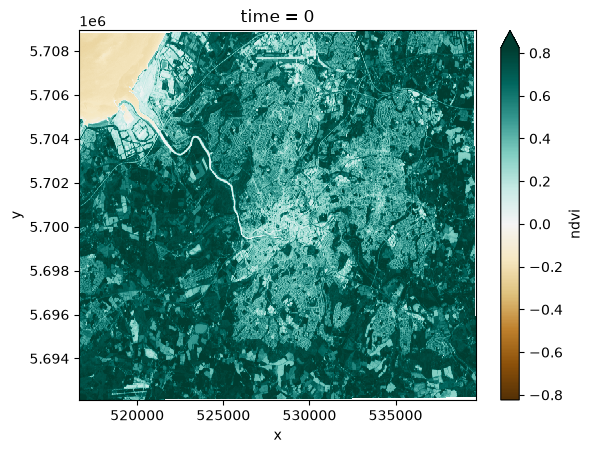

In [15]:
ndvi = ds['ndvi'].squeeze()

ndvi.plot.imshow(cmap="BrBG", robust=True)

There we have it: our Google Earth Engine object, safely off the cloud and within our Python environment.

## Summary

So far, this is hopefully familiar stuff: we have learned a different tool/API, similar to `pystac`/STAC, to access cloud data such as Landsat imagery. Next, we will explore the real strength of cloud computing, which is that we can begin to take advantage of performing processing in the same location as all of our data, without needing to go through the task of downloading them all...